In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import warnings
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

# তোমার পাথ
path = '/content/drive/MyDrive/Thesis file/Feature_Extract_Formants/'

extractors = ['AlexNet', 'CustomCNN', 'DenseNet121', 'EfficientNetB0', 'InceptionV3',
              'MobileNetV2', 'ResNet50', 'VGG16', 'ViT', 'Xception']

classifiers = {
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(random_state=42)
}

results = pd.DataFrame(columns=['Feature Extractor'] + list(classifiers.keys()) + ['Best', 'Best Accuracy'])
results['Feature Extractor'] = extractors

for extractor in extractors:
    print(f'Processing {extractor} ...')

    f1_file = f'{path}F1_Features_{extractor}.csv'
    f3_file = f'{path}F3_Features_{extractor}.csv'   # ← এখানে F3 করা হয়েছে

    df1 = pd.read_csv(f1_file)
    df3 = pd.read_csv(f3_file)                      # ← df3 (আগে df2 ছিল)

    # লেবেল কলাম অটো ডিটেক্ট
    possible_label_cols = ['label', 'class', 'target', 'phoneme', 'category', 'Label', 'Class', 'phoneme_label']
    label_col = None
    for col in possible_label_cols:
        if col in df1.columns:
            label_col = col
            break

    if label_col is None:
        label_col = df1.columns[1]
        print(f"   → লেবেল কলাম ধরা হলো: {label_col}")

    # ক্লিন করি
    def clean_features(df):
        df = df.copy()
        drop_cols = [c for c in df.columns if any(x in c.lower() for x in ['filename', 'path', 'unnamed', 'index'])]
        df.drop(columns=drop_cols, errors='ignore', inplace=True)
        return df

    df1_clean = clean_features(df1)
    df3_clean = clean_features(df3)                  # ← df3_clean

    X1 = df1_clean.drop(columns=[label_col], errors='ignore')
    X3 = df3_clean.drop(columns=[label_col], errors='ignore')  # ← X3
    y = df1_clean[label_col]

    X = pd.concat([X1.reset_index(drop=True), X3.reset_index(drop=True)], axis=1)  # ← X3

    # স্প্লিট (stratify সমস্যা হলে ছেড়ে দেবে)
    try:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    except ValueError:
        print(f"   → {extractor}: stratify ছাড়া স্প্লিট করা হলো")
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    best_acc = 0
    best_name = ''

    for name, clf in classifiers.items():
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        acc = round(accuracy_score(y_test, y_pred), 4)
        results.loc[results['Feature Extractor'] == extractor, name] = acc
        if acc > best_acc:
            best_acc = acc
            best_name = name

    0
    results.loc[results['Feature Extractor'] == extractor, 'Best'] = best_name
    results.loc[results['Feature Extractor'] == extractor, 'Best Accuracy'] = best_acc

# সেভ — নাম চেঞ্জ করলাম যাতে বোঝা যায় F1+F3
output_file = path + 'Full_Summary_Table_F1_F3.xlsx'
results.to_excel(output_file, index=False)

print('\nসব শেষ! F1 + F3 এর এক্সেল তৈরি হয়ে গেছে!')
print(f"লোকেশন: {output_file}")
display(results)

Mounted at /content/drive
Processing AlexNet ...
Processing CustomCNN ...
Processing DenseNet121 ...
Processing EfficientNetB0 ...
Processing InceptionV3 ...
Processing MobileNetV2 ...
Processing ResNet50 ...
Processing VGG16 ...
Processing ViT ...
Processing Xception ...

সব শেষ! F1 + F3 এর এক্সেল তৈরি হয়ে গেছে!
লোকেশন: /content/drive/MyDrive/Thesis file/Feature_Extract_Formants/Full_Summary_Table_F1_F3.xlsx


,Feature Extractor,AdaBoost,Decision Tree,Extra Trees,Gradient Boosting,KNN,Logistic Regression,Naive Bayes,Random Forest,SVM,Best,Best Accuracy
0,AlexNet,0.9143,0.8476,0.9048,0.9048,0.8857,0.9429,0.7619,0.8857,0.9048,Logistic Regression,0.9429
1,CustomCNN,0.9143,0.7714,0.9048,0.8952,0.8762,0.8952,0.6762,0.8857,0.9143,AdaBoost,0.9143
2,DenseNet121,0.8952,0.7714,0.8571,0.9048,0.8571,0.9048,0.8381,0.8952,0.8476,Gradient Boosting,0.9048
3,EfficientNetB0,0.9333,0.8571,0.8762,0.9048,0.8286,0.9048,0.8571,0.8952,0.8762,AdaBoost,0.9333
4,InceptionV3,0.8571,0.7905,0.8476,0.8952,0.8381,0.9048,0.7905,0.8381,0.8952,Logistic Regression,0.9048
5,MobileNetV2,0.9143,0.8667,0.8762,0.9143,0.9143,0.9143,0.8381,0.9048,0.8571,AdaBoost,0.9143
6,ResNet50,0.9238,0.8667,0.8857,0.9429,0.819,0.8762,0.819,0.8857,0.8381,Gradient Boosting,0.9429
7,VGG16,0.9333,0.8095,0.9143,0.9143,0.9333,0.9524,0.819,0.9333,0.9333,Logistic Regression,0.9524
8,ViT,0.8381,0.8095,0.819,0.8667,0.8095,0.8952,0.7714,0.8286,0.8286,Logistic Regression,0.8952
9,Xception,0.9048,0.8,0.8667,0.8667,0.7524,0.8762,0.8286,0.8857,0.8476,AdaBoost,0.9048


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Final feature shape (F1+F3): (523, 50176)

Confusion Matrix (VGG16 + Logistic Regression):
[[36  3]
 [ 2 64]]


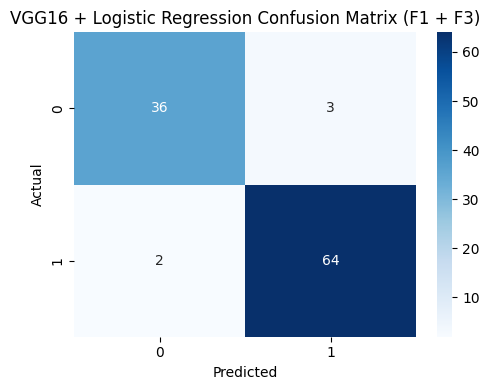


Performance Table (F1 + F3):


,Metric,Value (%)
0,Accuracy,95.24
1,Precision,95.52
2,Recall,96.97
3,F1-score,96.24



✅ Saved Files:
- Confusion Matrix: F1_F3_VGG16_Confusion_Matrix.png
- Performance Table: F1_F3_VGG16_Performance.xlsx


In [7]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
import seaborn as sns
import matplotlib.pyplot as plt
import os
import warnings
warnings.filterwarnings('ignore')

# ================= PATH =================
csv_path = '/content/drive/MyDrive/Thesis file/Feature_Extract_Formants/'
save_path = '/content/drive/MyDrive/Thesis file/Feature_Extract_Formants/Feature_Extract/'
os.makedirs(save_path, exist_ok=True)

# ================= BEST MODEL (F1 + F3) =================
extractor = 'VGG16'
model_name = 'Logistic Regression'
model = LogisticRegression(max_iter=2000, random_state=42)

# ================= LOAD FILES =================
df1 = pd.read_csv(f'{csv_path}F1_Features_{extractor}.csv')
df3 = pd.read_csv(f'{csv_path}F3_Features_{extractor}.csv')

# Label detect
label_col = None
for col in ['label', 'Label', 'class', 'Class']:
    if col in df1.columns:
        label_col = col
        break

y = df1[label_col]

def clean(df):
    drop_cols = [c for c in df.columns if any(x in c.lower()
                 for x in ['label','filename','path','unnamed','index'])]
    return df.drop(columns=drop_cols, errors='ignore')

X = pd.concat([
    clean(df1),
    clean(df3)
], axis=1)

print("Final feature shape (F1+F3):", X.shape)

# ================= TRAIN / TEST =================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# ================= CONFUSION MATRIX =================
cm = confusion_matrix(y_test, y_pred)
print(f"\nConfusion Matrix ({extractor} + {model_name}):\n{cm}")

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')  # 🔥 Different color
plt.title(f'{extractor} + {model_name} Confusion Matrix (F1 + F3)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig(f'{save_path}F1_F3_{extractor}_Confusion_Matrix.png')
plt.show()

# ================= PERFORMANCE TABLE =================
perf_table = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Value (%)': [
        round(accuracy_score(y_test, y_pred)*100, 2),
        round(precision_score(y_test, y_pred)*100, 2),
        round(recall_score(y_test, y_pred)*100, 2),
        round(f1_score(y_test, y_pred)*100, 2)
    ]
})

print("\nPerformance Table (F1 + F3):")
display(perf_table)

perf_table.to_excel(
    f'{save_path}F1_F3_{extractor}_Performance.xlsx',
    index=False
)

print("\n✅ Saved Files:")
print(f"- Confusion Matrix: F1_F3_{extractor}_Confusion_Matrix.png")
print(f"- Performance Table: F1_F3_{extractor}_Performance.xlsx")
